# Lo que un vector aprende del contexto: Word2Vec

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Una matriz de contextos para todo un idioma tendría billones de celdas casi vacías. |
| **Producto** | Tres funciones (pares de entrenamiento, vecinos y analogías), vecinos clasificados y una decisión de uso. |
| **Recursos** | Sección 1 y 2: poca memoria. Desde la 3: unos 2 GB (`SBW-vectors-300-min5.bin.gz`). Con poca memoria, `LIMITE_DE_PALABRAS = 200000`. |

En el cuaderno 01 armaste a mano el perfil de contexto de 30 palabras y lo comprimiste con SVD. Con un vocabulario real (más de un millón y medio de palabras) esa matriz tendría casi tres billones de celdas. Word2Vec invierte el camino: aprende directamente un vector corto por palabra intentando **predecir a sus vecinas**.

**Cuando el modelo devuelve las palabras más cercanas a otra, ¿de qué está hecha esa cercanía y cuándo es evidencia?**

> **Cómo se trabaja.** Explorás cada tema con el código ya escrito y las notas **Para mirar**. Al final de cada bloque, un **microlaboratorio** te dice qué líneas completar y con qué; la celda siguiente comprueba.

In [1]:
import sys
import time
import zlib
import importlib.metadata

import numpy as np
import pandas as pd
from IPython.display import display

from gensim.models import KeyedVectors, Word2Vec

import utils

# La semilla fija el azar del entrenamiento del modelo chico.
SEMILLA = 42

# None carga todo el vocabulario (1.692.025 palabras).
# Con poca memoria, proba con 200000.
LIMITE_DE_PALABRAS = None

pd.set_option("display.max_colwidth", 100)

print("Python:", sys.version.split()[0])
for paquete in ["gensim", "numpy", "pandas"]:
    print(f"{paquete}: {importlib.metadata.version(paquete)}")
print("Semilla:", SEMILLA, "| limite de palabras:", LIMITE_DE_PALABRAS)

Python: 3.12.13
gensim: 4.4.0
numpy: 2.5.4
pandas: 3.0.6
Semilla: 42 | limite de palabras: None


## 1. Los pares de los que aprende

El modelo nunca recibe un significado: recibe **pares (centro, contexto)**. Para cada palabra *centro* se anotan las que están a `VENTANA` palabras de distancia. Cambiá `VENTANA` a 1 y a 3 y mirá cuántos pares salen.

11 palabras, ventana 2: 38 pares


,centro,contexto
0,había,una
1,había,vez
2,una,había
3,una,vez
4,una,una
5,vez,había
6,vez,una
7,vez,una


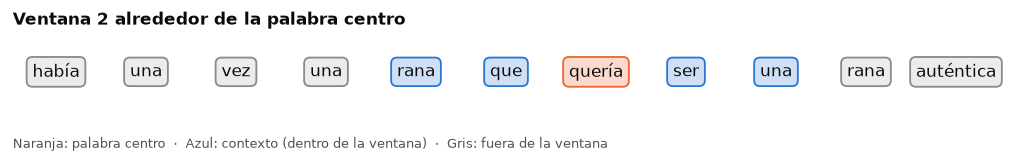

In [2]:
oracion = "Había una vez una rana que quería ser una rana auténtica"
palabras = utils.separar_palabras(oracion)

VENTANA = 2

pares = []
lugar_del_centro = 0
for centro in palabras:
    # La ventana no puede salirse de la oracion por ningun lado.
    desde = max(0, lugar_del_centro - VENTANA)
    hasta = min(len(palabras), lugar_del_centro + VENTANA + 1)
    for lugar_del_contexto in range(desde, hasta):
        if lugar_del_contexto != lugar_del_centro:
            pares.append({
                "centro": centro,
                "contexto": palabras[lugar_del_contexto],
            })
    lugar_del_centro += 1

tabla_de_pares = pd.DataFrame(pares)
print(f"{len(palabras)} palabras, ventana {VENTANA}: "
      f"{len(tabla_de_pares)} pares")
display(tabla_de_pares.head(8))

# La misma ventana, dibujada: el centro, su contexto y lo que queda afuera.
CENTRO = "quería"
lugar_elegido = palabras.index(CENTRO)
clases = []
lugar = 0
for palabra in palabras:
    if lugar == lugar_elegido:
        clases.append("centro")
    elif abs(lugar - lugar_elegido) <= VENTANA:
        clases.append("contexto")
    else:
        clases.append("fuera")
    lugar += 1
utils.dibujar_fichas(
    palabras, clases,
    estilos={
        "centro": (utils.NARANJA, "Naranja", "palabra centro"),
        "contexto": (utils.AZUL, "Azul", "contexto (dentro de la ventana)"),
        "fuera": (utils.GRIS, "Gris", "fuera de la ventana"),
    },
    titulo=f"Ventana {VENTANA} alrededor de la palabra centro",
    por_fila=11,
)

> **Para mirar.**
>
> - una oración de 11 palabras da 38 pares con ventana 2. Cada palabra aparece como centro y como contexto de otras. **Skip-gram** usa el centro para predecir cada contexto; **CBOW** usa todo el contexto junto para predecir el centro. Son los mismos pares leídos al revés.
> - la ventana es una decisión tuya: chica capta sintaxis cercana (*una rana*); grande, relaciones de tema.

## 2. Un modelo chico y sus límites

Entrenamos Word2Vec con los 137 fragmentos literarios del curso (unas 8.000 palabras). Los parámetros que importan:

| Parámetro | Qué significa | Qué cambia si lo modificás |
|---|---|---|
| `vector_size=50` | números por palabra | más dimensiones necesitan más datos |
| `window=5` | palabras a cada lado que cuentan | sintaxis (chica) o tema (grande) |
| `min_count=2` | se ignoran las palabras con una sola aparición | con 1, entran palabras de las que no se aprende nada |
| `sg=1` | 1 = Skip-gram, 0 = CBOW | cambia qué palabras raras quedan bien |
| `epochs=30` | vueltas sobre los textos | más épocas memorizan más |
| `workers=1` | hilos de cálculo | con más, el resultado varía entre ejecuciones |
| `hashfxn` | vector inicial de cada palabra | sin un hash estable, la misma semilla da otro resultado |

In [3]:
fragmentos = utils.cargar_fragmentos()

oraciones_para_entrenar = []
for texto in fragmentos["texto"]:
    oraciones_para_entrenar.append(utils.separar_palabras(texto))


def hash_estable(palabra: str) -> int:
    """Calcula un numero que depende solo de las letras de la palabra.

    El hash que trae Python cambia en cada sesion; este no.

    Args:
        palabra: La palabra a convertir.

    Returns:
        Un entero positivo.
    """
    return zlib.crc32(palabra.encode("utf-8"))


def entrenar_modelo_chico(semilla: int) -> Word2Vec:
    """Entrena un Word2Vec Skip-gram con los fragmentos del curso.

    Args:
        semilla: Semilla del azar del entrenamiento.

    Returns:
        El modelo entrenado.
    """
    return Word2Vec(
        sentences=oraciones_para_entrenar,
        vector_size=50, window=5, min_count=2, sg=1, epochs=30,
        seed=semilla, workers=1, hashfxn=hash_estable,
    )


modelo_chico = entrenar_modelo_chico(SEMILLA)
otro_modelo_chico = entrenar_modelo_chico(SEMILLA + 1)
print("Palabras que aprendio:", len(modelo_chico.wv.key_to_index))

# Comparamos los vecinos de dos entrenamientos que difieren solo en la semilla.
for palabra in ["muerte", "hombre", "casa", "tiempo"]:
    assert palabra in modelo_chico.wv.key_to_index, f"Falta {palabra}."
    primeros = modelo_chico.wv.most_similar(positive=[palabra], topn=5)
    segundos = otro_modelo_chico.wv.most_similar(positive=[palabra], topn=5)
    nombres_1 = []
    for vecino, coseno in primeros:
        nombres_1.append(vecino)
    nombres_2 = []
    for vecino, coseno in segundos:
        nombres_2.append(vecino)
    en_comun = set(nombres_1) & set(nombres_2)
    print(f"{palabra}: semilla {SEMILLA}: {nombres_1}")
    print(f"{' ' * len(palabra)}  semilla {SEMILLA + 1}: {nombres_2}")
    print(f"{' ' * len(palabra)}  en comun: {len(en_comun)} de 5")

Palabras que aprendio: 703
muerte: semilla 42: ['quijano', 'alonso', 'muerto', 'aldea', 'sino']
        semilla 43: ['hermosa', 'aldea', 'papeles', 'quijano', 'muerto']
        en comun: 3 de 5
hombre: semilla 42: ['menos', 'subir', 'papeles', 'muerte', 'mundo']
        semilla 43: ['menos', 'muerte', 'recorrer', 'esperanza', 'muros']
        en comun: 2 de 5
casa: semilla 42: ['suelo', 'salió', 'cinco', 'recuerdos', 'con']
      semilla 43: ['salió', 'suelo', 'vientre', 'mujer', 'bajo']
      en comun: 2 de 5
tiempo: semilla 42: ['mismo', 'hace', 'primeros', 'descansará', 'llegado']
        semilla 43: ['mismo', 'en', 'hace', 'rey', 'llegado']
        en comun: 3 de 5


> **Para mirar.**
>
> - con dos semillas, coinciden entre 2 y 3 vecinos de 5. Y *muerte* queda junto a *quijano* y *alonso*: palabras del mismo cuento. Con 8.000 palabras, cada una aparece poco y lo aprendido depende del azar y del cuento, no de una estructura del español.
> - este modelo sirve para **ver el mecanismo**, no para sacar conclusiones sobre palabras. Por eso se usan vectores preentrenados con miles de millones de palabras.

### Microlaboratorio 1 — Generar los pares de entrenamiento

**Tarea.** Convertir el bucle de la sección 1 en una función reutilizable.  
**Producto.** `pares_centro_contexto`, comprobada con tres ventanas distintas.  
**Antes de empezar.** Sección 1.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `desde` | la primera posición de la ventana | el mayor entre `0` y `lugar - ventana` (función `max`) |
| (2) `hasta` | la posición siguiente a la última | el menor entre `len(palabras)` y `lugar + ventana + 1` (función `min`) |
| (3) `par` | un diccionario con dos claves | `{"centro": ..., "contexto": ...}` con la palabra centro y la palabra de la posición `lugar_del_contexto` |

**Comprobación.** con la oración de la sección 1, la ventana 1 da 20 pares, la 2 da 38 y la 3 da 54; y el contexto de *quería* con ventana 2 es `rana, que, ser, una`.

> **Ayuda 1.** Es el mismo bucle de la sección 1, sin los `print`.  
> **Ayuda 2.** Las líneas (1) y (2) son las que evitan que la ventana se salga de la oración por la izquierda y por la derecha.

In [4]:
def pares_centro_contexto(palabras: list, ventana: int) -> list:
    """Genera los pares (centro, contexto) de una oracion.

    Args:
        palabras: La oracion, ya separada en palabras.
        ventana: Cuantas palabras a cada lado cuentan como contexto.

    Returns:
        Lista de diccionarios con las claves "centro" y "contexto".
    """
    pares = []
    lugar = 0
    for centro in palabras:
        desde = 0  # COMPLETAR (1)
        hasta = 0  # COMPLETAR (2)
        for lugar_del_contexto in range(desde, hasta):
            if lugar_del_contexto != lugar:
                par = {}  # COMPLETAR (3)
                pares.append(par)
        lugar += 1
    return pares


cantidades = []
for ventana_de_prueba in [1, 2, 3]:
    cantidades.append(len(pares_centro_contexto(palabras, ventana_de_prueba)))
utils.comprobar(
    cantidades == [20, 38, 54],
    f"revisa (1), (2) y (3): se esperaban [20, 38, 54] y salio {cantidades}",
)

contexto_de_queria = []
for par in pares_centro_contexto(palabras, 2):
    if par.get("centro") == "quería":
        contexto_de_queria.append(par["contexto"])
utils.comprobar(
    contexto_de_queria == ["rana", "que", "ser", "una"],
    "revisa (3): el contexto de queria deberia ser rana, que, ser, una",
)

Todavia falta. Pista: revisa (1), (2) y (3): se esperaban [20, 38, 54] y salio [0, 0, 0]
Todavia falta. Pista: revisa (3): el contexto de queria deberia ser rana, que, ser, una


## 3. Un modelo con miles de millones de palabras

Cada vecino que veas hereda las voces del corpus de este modelo:

| Campo | Contenido |
|---|---|
| Nombre | Spanish Billion Words Corpus and Embeddings (SBWCE), Cristian Cardellino, marzo de 2016 · <https://crscardellino.net/SBWCE/> |
| Corpus | SenSem, Ancora y Tibidabo; OPUS (libros, legislación de la Unión Europea, comentarios de noticias, documentos de la ONU); Parlamento Europeo; Wikipedia, Wikisource y Wikibooks de 2015. Cerca de 1.500 millones de palabras |
| Técnica | Skip-gram con muestreo negativo, 300 dimensiones, `min_count=5` |
| Licencia | CC BY-SA 4.0 |
| Archivo | 1.692.025 entradas (la ficha menciona 1.000.653 tokens únicos; no pudimos reconciliar la diferencia) |
| Límites previsibles | Anterior a 2016: no tiene *covid* ni *guasap*. Fuentes institucionales y enciclopédicas, con poca lengua oral o juvenil |

In [5]:
inicio_de_la_carga = time.perf_counter()
vectores = utils.cargar_vectores_word2vec(limite=LIMITE_DE_PALABRAS)
segundos = time.perf_counter() - inicio_de_la_carga

cantidad = len(vectores.key_to_index)
print("Tipo:", type(vectores).__name__)
print(f"Palabras: {cantidad:,} | dimensiones: {vectores.vector_size} | "
      f"carga: {segundos:.0f} s")
# Las entradas vienen ordenadas por frecuencia.
print("Primeras entradas:", list(vectores.key_to_index)[:8])

# El tamano del problema que mencionamos al comienzo.
celdas_de_la_matriz = cantidad ** 2
numeros_de_la_tabla = cantidad * vectores.vector_size
print(f"Matriz de contextos: {celdas_de_la_matriz:,} celdas")
print(f"Tabla de vectores: {numeros_de_la_tabla:,} numeros")

# La similitud de gensim es el mismo coseno del cuaderno 01.
a_mano = utils.coseno(vectores["padre"], vectores["papá"])
de_gensim = float(vectores.similarity("padre", "papá"))
assert abs(a_mano - de_gensim) < 1e-4, "El coseno no coincide."
print(f"padre ~ papa: {a_mano:.2f} (a mano) | {de_gensim:.2f} (gensim)")

Tipo: KeyedVectors
Palabras: 1,692,025 | dimensiones: 300 | carga: 9 s
Primeras entradas: ['<PUNCTUATION>', 'de', 'el', 'la', 'en', 'y', '<NUMBER>', 'que']
Matriz de contextos: 2,862,948,600,625 celdas
Tabla de vectores: 507,607,500 numeros
padre ~ papa: 0.58 (a mano) | 0.58 (gensim)


> **Para mirar.**
>
> - la tabla guarda unos 500 millones de números, frente a casi tres billones de celdas de la matriz de contextos: esa es la compresión.
> - el archivo trae marcas como `<NUMBER>`, nombres con guion bajo (`Buenos_Aires`) y formas con mayúscula y minúscula como entradas separadas: *Rey* y *rey* son distintas.
> - una palabra que no está no tiene vector. Es el límite que abre el cuaderno siguiente.

## 4. Qué clase de cercanía devuelve

Pedimos los vecinos de una palabra: es el mismo coseno, calculado contra 1,7 millones de entradas. Para leerlos usamos seis categorías:

| Categoría | Qué es |
|---|---|
| sinonimia | mismo significado (*rey* ~ *monarca*) |
| oposición | significado contrario (*bueno* ~ *malo*) |
| tema o campo | pertenece al mismo mundo (*rey* ~ *reino*) |
| morfología | otra forma de la misma palabra (*rey* ~ *reyes*, *Rey*) |
| entidad | nombre propio relacionado (*Alfonso_V_de_León*) |
| ruido | otra lengua, nombre de especie, error del corpus |

rey -> monarca, Rey, príncipe, reyes, reino, Alfonso_V_de_León, Adonías, reina
bueno -> malo, divertido, gracioso, lindo, buen, feo, genial, asqueroso
madre -> padre, hija, hermana, esposa, abuela, hijo, tía, marido
mate -> mates, hiera, dispare, cace, pegue, atrape, mata, maten


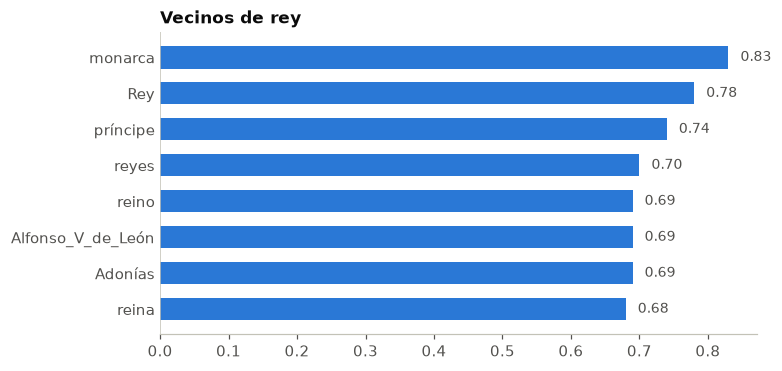

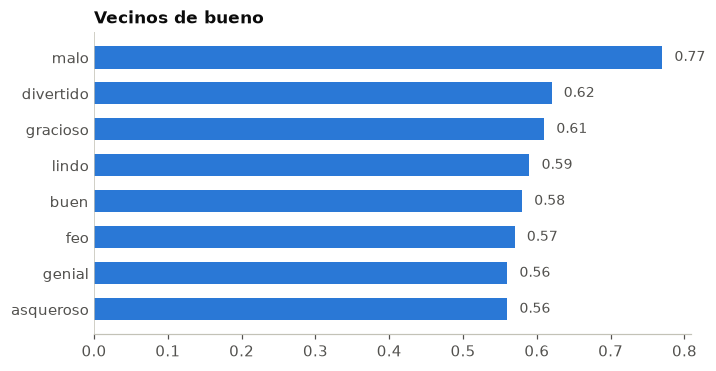

In [6]:
def mostrar_vecinos(
    vectores: KeyedVectors, palabras: list, cantidad: int = 8
) -> None:
    """Imprime una linea por palabra con sus vecinos mas cercanos.

    Args:
        vectores: Modelo con vectores (gensim).
        palabras: Palabras a consultar.
        cantidad: Cuantos vecinos mostrar de cada una.
    """
    for palabra in palabras:
        if palabra not in vectores.key_to_index:
            print(f"{palabra} -> no esta en el vocabulario")
            continue
        vecinos = vectores.most_similar(positive=[palabra], topn=cantidad)
        nombres = []
        for vecino, coseno in vecinos:
            nombres.append(vecino)
        print(f"{palabra} -> {', '.join(nombres)}")


mostrar_vecinos(vectores, ["rey", "bueno", "madre", "mate"])

# Los mismos vecinos de rey y bueno, con su coseno.
for palabra in ["rey", "bueno"]:
    nombres = []
    cosenos = []
    for vecino, coseno in vectores.most_similar(positive=[palabra], topn=8):
        nombres.append(vecino)
        cosenos.append(round(float(coseno), 2))
    utils.dibujar_barras(nombres, cosenos, f"Vecinos de {palabra}")

> **Para mirar.**
>
> - *rey* es el caso favorable: *monarca* (sinonimia), *Rey* y *reyes* (morfología), *príncipe*, *reino*, *reina* (campo), *Alfonso_V_de_León* y *Adonías* (entidades). Casi todo sirve para agrupar un campo.
> - *bueno* complica: su primer vecino es *malo*, un antónimo. Para separar opiniones positivas de negativas, es una mala señal.
> - *madre* trae ocho parientes, del mismo campo. *mate* no trae la bebida: además de *mates*, son formas verbales (*hiera*, *dispare*, *cace*, *mata*…). Una explicación posible: *mate* es también una forma de *matar* («que yo mate»). Es una hipótesis; sin el corpus no se puede comprobar.

In [7]:
mostrar_vecinos(vectores, ["laburo", "guasap", "che", "bondi"], 6)

laburo -> marío, labura, despelote, condenao, dejás, p'atrás
guasap -> no esta en el vocabulario
che -> è, questo, ciò, quello, più, stessa
bondi -> Calopteryx, Labrus, Aulostomus, Chrysophlegma, Molossus, morenoi


> **Para mirar.**
>
> - *laburo* trae vecinos orales (*labura*, *despelote*, *dejás*) y alguno sin relación (*marío*). *guasap* no está.
> - *che* devuelve palabras en italiano (*è*, *questo*, *ciò*) y *bondi*, nombres de especies (*Calopteryx*, *Labrus*). Hipótesis: en el corpus *che* pesa más como palabra del italiano, y *bondi* aparece sobre todo en nombres científicos. No se pueden confirmar sin el corpus.

In [8]:
mostrar_vecinos(vectores, ["banco", "pibe"], 6)

banco -> bancos, Banco_Central, Banco, Citybank, HSBC, Cantor_Fitzgerald


pibe -> votá, chabón, viejito, p'atrás, desconfiao, boludo


> **Para mirar.**
>
> - *banco* devuelve entidades financieras (*Banco_Central*, *HSBC*), no el asiento de una plaza: un único vector resume el sentido dominante.
> - *pibe* trae voseo y lunfardo (*votá*, *chabón*, *boludo*). Para un uso en Argentina, quién escribió el corpus es el criterio de elección, no un detalle.

### Microlaboratorio 2 — Vecinos y clasificación

**Tarea.** Escribir la función de vecinos y clasificar los de *madre* y *mate*.  
**Producto.** `vecinos_de` comprobada, la clasificación completa y los vecinos de tres palabras de un contexto de uso.  
**Antes de empezar.** Secciones 3 y 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `vecinos` | la lista de pares (vecino, coseno) | el método `vectores.most_similar` con dos argumentos con nombre: `positive` (una lista con la palabra) y `topn` (la cantidad) |
| (2) `nombre` | solo la palabra de cada par | dentro del bucle, la variable `vecino` |
| Paso 2 `clasificacion` | una categoría por vecino | una de estas, **sin tilde**: `sinonimia`, `oposicion`, `tema`, `morfologia`, `entidad`, `ruido` |
| Paso 3 `tres_palabras` | tus tres palabras | una lista de 3 textos de un contexto donde un sistema decide (corrector, buscador escolar, filtro de currículums) |

**Comprobación.** `vecinos_de(vectores, "rey", 3)` debe dar `monarca, Rey, príncipe`; para una palabra ausente, una lista vacía; y la clasificación no puede dejar vecinos en `pendiente`.

> **Ayuda 1.** Es la misma llamada que usa `mostrar_vecinos`, pero devolviendo la lista en lugar de imprimirla.  
> **Ayuda 2.** Si la palabra no está en `vectores.key_to_index`, la función ya devuelve la lista vacía antes de llegar a tus líneas.

In [9]:
def vecinos_de(
    vectores: KeyedVectors, palabra: str, cantidad: int = 8
) -> list:
    """Busca las palabras mas cercanas a una palabra.

    Args:
        vectores: Modelo con vectores (gensim).
        palabra: La palabra a consultar.
        cantidad: Cuantos vecinos devolver.

    Returns:
        Lista con los nombres de los vecinos, del mas cercano al mas lejano.
        Si la palabra no esta en el vocabulario, una lista vacia.
    """
    if palabra not in vectores.key_to_index:
        return []
    vecinos = []  # COMPLETAR (1)
    nombres = []
    for vecino, coseno in vecinos:
        nombre = ""  # COMPLETAR (2)
        nombres.append(nombre)
    return nombres


utils.comprobar(
    vecinos_de(vectores, "rey", 3) == ["monarca", "Rey", "príncipe"]
    and vecinos_de(vectores, "guasap") == [],
    "revisa (1) y (2): rey -> monarca, Rey, principe; guasap -> lista vacia",
)

# PASO 2: reemplaza cada "pendiente" por una categoria.
CATEGORIAS = [
    "sinonimia", "oposicion", "tema", "morfologia", "entidad", "ruido",
    "pendiente",
]
clasificacion = {
    "madre": {
        "padre": "pendiente", "hija": "pendiente", "hermana": "pendiente",
        "esposa": "pendiente", "abuela": "pendiente", "hijo": "pendiente",
        "tía": "pendiente", "marido": "pendiente",
    },
    "mate": {
        "mates": "pendiente", "hiera": "pendiente", "dispare": "pendiente",
        "cace": "pendiente", "pegue": "pendiente", "atrape": "pendiente",
        "mata": "pendiente", "maten": "pendiente",
    },
}
sin_clasificar = 0
for palabra, vecinos in clasificacion.items():
    conteo = {}
    for vecino, categoria in vecinos.items():
        assert categoria in CATEGORIAS, f"'{categoria}' no es valida."
        conteo[categoria] = conteo.get(categoria, 0) + 1
        if categoria == "pendiente":
            sin_clasificar += 1
    print(palabra, "->", conteo)
utils.comprobar(sin_clasificar == 0, f"quedan {sin_clasificar} pendientes")

# PASO 3: cambia estas tres palabras por las tuyas.
tres_palabras = ["laburo", "trabajo", "empleo"]
for palabra in tres_palabras:
    print(palabra, "->", vecinos_de(vectores, palabra))

Todavia falta. Pista: revisa (1) y (2): rey -> monarca, Rey, principe; guasap -> lista vacia
madre -> {'pendiente': 8}
mate -> {'pendiente': 8}
Todavia falta. Pista: quedan 16 pendientes
laburo -> []
trabajo -> []
empleo -> []


## 5. Donde la cercanía deja de ser evidencia

Si los vecinos sirven, ¿se puede fijar un umbral de coseno que separe «similar» de «no similar»? Probamos con pares de distinto tipo.

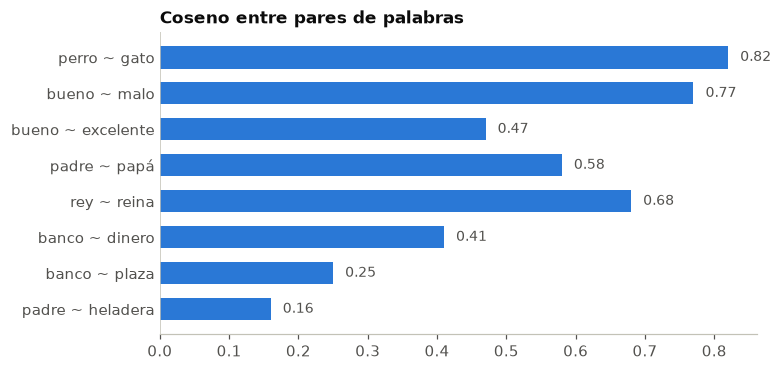

In [10]:
pares_de_palabras = [
    ("perro", "gato"), ("bueno", "malo"), ("bueno", "excelente"),
    ("padre", "papá"), ("rey", "reina"), ("banco", "dinero"),
    ("banco", "plaza"), ("padre", "heladera"),
]

nombres = []
cosenos = []
for palabra_a, palabra_b in pares_de_palabras:
    coseno_del_par = float(vectores.similarity(palabra_a, palabra_b))
    nombres.append(f"{palabra_a} ~ {palabra_b}")
    cosenos.append(round(coseno_del_par, 2))
utils.dibujar_barras(nombres, cosenos, "Coseno entre pares de palabras")

> **Para mirar.**
>
> - *bueno ~ malo* (0,77) es mayor que *bueno ~ excelente* (0,47), y *padre ~ papá* (0,58), casi sinónimos, queda por debajo de *perro ~ gato* (0,82). El coseno mide cuánto **contexto** comparten dos palabras, no cuánto significan lo mismo; los antónimos comparten casi todo.
> - no hay un umbral universal («0,5 es similar»): cualquier umbral hay que justificarlo con ejemplos de tu caso.

**Analogías.** La suma y resta de vectores (*rey − hombre + mujer*) suele presentarse como prueba de que el modelo capta relaciones. Para no mostrar solo lo que funciona, elegimos las ocho analogías y sus respuestas **antes de ejecutar**.

In [11]:
analogias = [
    {"a": "rey", "b": "hombre", "c": "mujer", "esperada": "reina"},
    {"a": "París", "b": "Francia", "c": "España", "esperada": "Madrid"},
    {"a": "Madrid", "b": "España", "c": "Argentina",
     "esperada": "Buenos_Aires"},
    {"a": "Roma", "b": "Italia", "c": "Francia", "esperada": "París"},
    {"a": "padre", "b": "hombre", "c": "mujer", "esperada": "madre"},
    {"a": "Buenos_Aires", "b": "Argentina", "c": "Uruguay",
     "esperada": "Montevideo"},
    {"a": "grande", "b": "pequeño", "c": "bueno", "esperada": "malo"},
    {"a": "rápido", "b": "lento", "c": "alto", "esperada": "bajo"},
]

aciertos = 0
for analogia in analogias:
    candidatos = vectores.most_similar(
        positive=[analogia["a"], analogia["c"]],
        negative=[analogia["b"]],
        topn=5,
    )
    nombres = []
    for candidata, coseno in candidatos:
        nombres.append(candidata)
    if nombres[0] == analogia["esperada"]:
        aciertos += 1
    print(f"{analogia['a']} - {analogia['b']} + {analogia['c']} -> "
          f"{nombres} (esperada: {analogia['esperada']})")
print(f"\nAcierto en primer lugar: {aciertos} de {len(analogias)}")

rey - hombre + mujer -> ['reina', 'princesa', 'consorte', 'Alfonso_V_de_León', 'esposa'] (esperada: reina)


París - Francia + España -> ['Madrid', 'Sevilla', 'Valladolid', 'Barcelona', 'Valencia'] (esperada: Madrid)


Madrid - España + Argentina -> ['Buenos_Aires', 'Mar_de_el_Plata', 'La_Plata', 'Capital_Federal', 'Bahía_Blanca'] (esperada: Buenos_Aires)
Roma - Italia + Francia -> ['París', 'Aviñón', 'Ruan', 'Reims', 'Bourges'] (esperada: París)


padre - hombre + mujer -> ['madre', 'hija', 'esposa', 'hermana', 'cuñada'] (esperada: madre)


Buenos_Aires - Argentina + Uruguay -> ['Montevideo', 'Paysandú', 'Corrientes', 'Concepción_de_el_Uruguay', 'Asunción_de_el_Paraguay'] (esperada: Montevideo)


grande - pequeño + bueno -> ['malo', 'hacedera', 'humildoso', 'verdad', 'buena'] (esperada: malo)
rápido - lento + alto -> ['elevado', 'grande', 'alta', 'fuerte', 'altos'] (esperada: bajo)

Acierto en primer lugar: 7 de 8


> **Para mirar.**
>
> - acierta las capitales y los pares *rey/reina* y *padre/madre*; falla en *rápido − lento + alto* (devuelve *elevado*, *grande*, *alta*, no *bajo*).
> - la resta aísla una dirección que el corpus repite mucho (capital de país); en relaciones menos repetidas esa dirección no está bien definida. Ocho analogías elegidas por nosotros no estiman una tasa de acierto: muestran que **depende de qué relación se pruebe**.

### Microlaboratorio 3 — Analogías y decisión de uso

**Tarea.** Escribir la función de analogías, proponer un caso que creas que falla y decidir qué uso es razonable.  
**Producto.** `analogia` comprobada, una analogía propia con su resultado y una decisión escrita.  
**Antes de empezar.** Secciones 4 y 5.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `candidatos` | los 5 candidatos (palabra, coseno) | `vectores.most_similar` con tres argumentos con nombre: `positive` (lista con `a` y `c`), `negative` (lista con `b`) y `topn` |
| (2) `mejor` | solo la palabra del primer candidato | el primer elemento (`[0]`) del primer par (`[0]`) de `candidatos` |
| Paso 2 `mi_analogia` | cuatro valores | palabras **que estén en el vocabulario** (con la mayúscula y el guion bajo de las entradas, como `Buenos_Aires`) |
| Paso 3 `mi_decision` | una o dos oraciones | un contexto (corrector o buscador en Argentina, filtro de currículums), qué error sería aceptable y cuál no, apoyado en un vecindario de este cuaderno |

**Comprobación.** `analogia(vectores, "rey", "hombre", "mujer")` debe dar `reina` y `Madrid - España + Argentina` debe dar `Buenos_Aires`.

> **Ayuda 1.** La estructura es la de la celda de analogías de la sección 5, dentro de una función.  
> **Ayuda 2.** Una analogía que probablemente falle: una relación poco repetida en los textos, como antónimos de adjetivos.

In [12]:
def analogia(
    vectores: KeyedVectors, a: str, b: str, c: str, cantidad: int = 5
) -> str:
    """Resuelve la analogia "a es a b como c es a ?".

    Args:
        vectores: Modelo con vectores (gensim).
        a: Primera palabra.
        b: Palabra que se resta.
        c: Palabra que se suma.
        cantidad: Cuantos candidatos pedir al modelo.

    Returns:
        La palabra mas cercana al vector a - b + c.
    """
    candidatos = []  # COMPLETAR (1)
    mejor = ""  # COMPLETAR (2)
    return mejor


utils.comprobar(
    analogia(vectores, "rey", "hombre", "mujer") == "reina"
    and analogia(vectores, "Madrid", "España", "Argentina") == "Buenos_Aires",
    "revisa (1) y (2): rey - hombre + mujer = reina",
)

# PASO 2: proba una analogia que creas que falla.
mi_analogia = {"a": "rápido", "b": "lento", "c": "alto", "esperada": "bajo"}
for clave in ["a", "b", "c"]:
    assert mi_analogia[clave] in vectores.key_to_index, f"Falta {clave}."
resultado = analogia(vectores, mi_analogia["a"], mi_analogia["b"],
                     mi_analogia["c"])
print(f"Esperada: {mi_analogia['esperada']} | devolvio: {resultado}")

# PASO 3: tu decision entre las comillas.
mi_decision = ""
utils.comprobar(
    len(mi_decision.split()) >= 8,
    "escribi al menos una oracion completa en mi_decision",
)

Todavia falta. Pista: revisa (1) y (2): rey - hombre + mujer = reina
Esperada: bajo | devolvio: 
Todavia falta. Pista: escribi al menos una oracion completa en mi_decision


## Qué te llevás

- Word2Vec aprende **vectores cortos prediciendo vecinas**; la tabla ocupa una fracción de la matriz de contextos.
- El coseno mide **contexto compartido**, no sinonimia: aparecen antónimos, formas verbales, otras lenguas.
- Una analogía lograda es un comportamiento observado en ciertos casos, no una ley. Y todo vecino hereda las voces del corpus.

**Sigue:** qué pasa con una palabra que el modelo nunca vio (cuaderno 03).